In [ ]:
!pip install xgboost -q

In [ ]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    median_absolute_error,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor



In [ ]:
def normalize_digits_fa2en(text: str) -> str:

    if text is None:
        return ""
    if isinstance(text, float) and np.isnan(text):
        return ""
    s = str(text)
    trans = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")
    return s.translate(trans)

In [ ]:
def normalize_persian_text(text: str) -> str:

    if text is None:
        return ""
    if isinstance(text, float) and np.isnan(text):
        return ""
    s = str(text)
    s = s.replace("\u200c"," ").replace("‌"," ")
    s = s.replace("ي","ی").replace("ك","ک")
    s = normalize_digits_fa2en(s)
    s = s.lower()
    s = re.sub(r"\s+"," ", s).strip()
    return s

In [ ]:

def parse_int_from_str(text: str):

    s = normalize_digits_fa2en(text)
    nums = re.findall(r"\d+", s)
    if not nums:
        return np.nan
    main = max(nums, key=len)
    try:
        return int(main)
    except Exception:
        return np.nan


try:
    df = pd.read_csv("cars_features_merged_no_negotiable.csv", encoding="utf-8-sig")
    print("[INFO] CSV loaded with utf-8-sig")
except Exception as e:
    print("[WARN] utf-8-sig failed, trying default encoding. Error:", e)
    df = pd.read_csv("cars_features_merged_no_negotiable.csv")
    print("[INFO] CSV loaded with default encoding")

print("col s:", list(df.columns))

assert "price_raw" in df.columns, "col price_raw no exist ."
assert "price" in df.columns, "don exist price in this raw"


dedup_subset = [c for c in ["title", "year_raw", "mileage_km", "price_raw"] if c in df.columns]
if dedup_subset:
    before_dedup = len(df)
    df = df.drop_duplicates(subset=dedup_subset, keep="first").copy()
    print(f"[INFO] duplicate: {before_dedup - len(df)}")

df["price_raw_str"] = df["price_raw"].fillna("").astype(str)
df["price_raw_norm"] = df["price_raw_str"].apply(normalize_persian_text)

mask_tavafog = df["price_raw_norm"].str.contains("توافق")
print("tavafoghi del:", int(mask_tavafog.sum()))
df = df.loc[~mask_tavafog].copy()


df["price_str"] = df["price"].fillna("").astype(str)
df["price_num"] = df["price_str"].apply(parse_int_from_str).astype("float64")
df["price_raw_num"] = df["price_raw_str"].apply(parse_int_from_str).astype("float64")

df["price_final"] = df["price_num"]
mask_missing = df["price_final"].isna() | (df["price_final"] <= 0)
df.loc[mask_missing, "price_final"] = df.loc[mask_missing, "price_raw_num"]

before_drop = len(df)
df = df[df["price_final"].notna() & (df["price_final"] > 0)].copy()
after_drop = len(df)
print("tavafoghi price del:", before_drop - after_drop)

print(df["price_final"].describe().apply(lambda x: f"{x:,.0f}"))


df["price_final_million"] = df["price_final"] / 1_000_000.0

print("\nprice_final_million (milion):")
print(df["price_final_million"].describe().apply(lambda x: f"{x:,.3f}"))

q_low, q_hi = df["price_final_million"].quantile([0.01, 0.99])
df = df[(df["price_final_million"] >= q_low) & (df["price_final_million"] <= q_hi)].copy()

print(df["price_final_million"].describe().apply(lambda x: f"{x:,.3f}"))
print("shape", df.shape)


print(df.select_dtypes(include=[np.number]).isna().sum().sum())




TARGET_COL = "price_final_million"

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = [
    TARGET_COL,
    "price_final",
    "price_num",
    "price_raw_num",
]

feature_cols = [c for c in numeric_cols if c not in exclude_cols]

X = df[feature_cols].copy()
y = df[TARGET_COL].astype(float).copy()



price_bins = np.quantile(y, [0, 1/3, 2/3, 1])

y_class = np.digitize(y, price_bins[1:-1], right=False)

X_train, X_test, y_train, y_test, y_class_train, y_class_test = train_test_split(
    X, y, y_class, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)



metrics_results = {}
trained_models = {}

[INFO] CSV loaded with utf-8-sig
col s: ['source', 'title', 'body_status', 'engine_status', 'chassis_status', 'year_raw', 'price_raw', 'price', 'mileage_km', 'text_all', 'درب رنگ', 'درب تعویض', 'درب بدون رنگ', 'کاپوت تعویض', 'کاپوت بدون رنگ', 'درب صندوق رنگ', 'درب صندوق بدون رنگ', 'شاسی ضرب خوردگی', 'شاسی پلمپ', 'شاسی سالم', 'سقف رنگ', 'سقف بدون رنگ', 'ستون ها سالم', 'ستون ها ضرب دیدگی', 'گلگیر رنگ شدگی', 'گلگیر بدون رنگ', 'گلگیر تعویض', 'فنی سالم', 'فنی نیاز به تعمیر', 'فنی تعمیر شده', 'گیربکس سالم', 'گیر بکس نیاز به تعمیر', 'یک لکه رنگ', 'دو لکه رنگ', 'دور رنگ']
[INFO] duplicate: 399
tavafoghi del: 0
tavafoghi price del: 21
count               11,654
mean         1,192,583,957
std         38,939,938,395
min                     20
25%            285,000,000
50%            518,000,000
75%            860,000,000
max      4,200,000,000,000
Name: price_final, dtype: object

price_final_million (milion):
count       11,654.000
mean         1,192.584
std         38,939.938
min              

Fitting 5 folds for each of 20 candidates, totalling 100 fits

 best hyper param for ElasticNet:
{'model__l1_ratio': np.float64(0.9473684210526315), 'model__alpha': np.float64(0.001082636733874054)}

=== ElasticNet (milion) ===
R2        : 0.9889
MAE       : 36.661 milion
RMSE      : 86.589 milion
MSE       : 7497.651
MAPE      : 15.1787
MedAE     : 7.148 milion
Accuracy  : 0.9742
Precision : 0.9732 (macro)
Recall    : 0.9735 (macro)
F1-score  : 0.9732 (macro)

=== LinearRegression (milion) ===
R2        : 0.9889
MAE       : 36.676 milion
RMSE      : 86.587 milion
MSE       : 7497.286
MAPE      : 15.1781
MedAE     : 7.132 milion
Accuracy  : 0.9742
Precision : 0.9732 (macro)
Recall    : 0.9735 (macro)
F1-score  : 0.9732 (macro)
Fitting 3 folds for each of 20 candidates, totalling 60 fits

 best hyper param for XGBoost:
{'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__n_estimators': 400, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}

=== X

,R2,MAE,MSE,RMSE,MAPE,MedAE,ACC,Precision,Recall,F1
ElasticNet,0.988895,36.661031,7497.651021,86.588977,15.178652,7.148461,0.974179,0.973216,0.973456,0.973199
LinearRegression,0.988895,36.675738,7497.285508,86.586867,15.178106,7.131819,0.974179,0.973216,0.973456,0.973199
XGBoost,0.998159,7.796164,1243.123052,35.257950,0.215707,1.375000,0.994748,0.994515,0.994521,0.994487
RandomForest,0.999987,0.713880,9.061826,3.010287,0.019675,0.205106,1.000000,1.000000,1.000000,1.000000


,R2,MAE,MSE,RMSE,MAPE,MedAE
ElasticNet,0.988895,36.661031,7497.651021,86.588977,15.178652,7.148461
LinearRegression,0.988895,36.675738,7497.285508,86.586867,15.178106,7.131819
XGBoost,0.998159,7.796164,1243.123052,35.257950,0.215707,1.375000
RandomForest,0.999987,0.713880,9.061826,3.010287,0.019675,0.205106


,ACC,Precision,Recall,F1
ElasticNet,0.974179,0.973216,0.973456,0.973199
LinearRegression,0.974179,0.973216,0.973456,0.973199
XGBoost,0.994748,0.994515,0.994521,0.994487
RandomForest,1.000000,1.000000,1.000000,1.000000


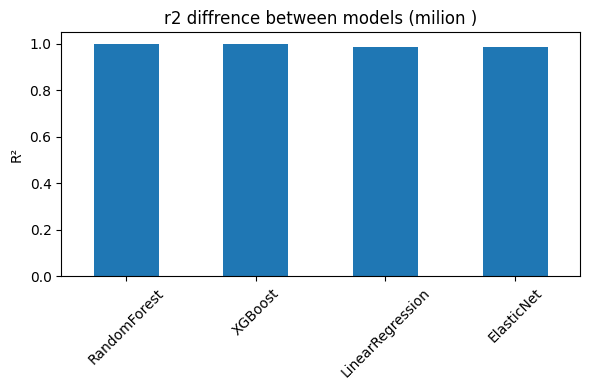

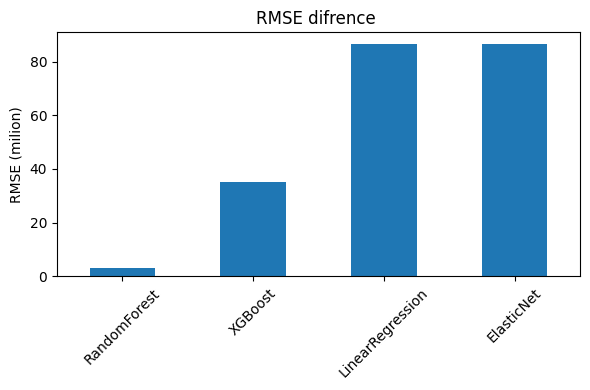

real sample for test 


,price,mileage_km,درب رنگ,درب تعویض,درب بدون رنگ,کاپوت تعویض,کاپوت بدون رنگ,درب صندوق رنگ,درب صندوق بدون رنگ,شاسی ضرب خوردگی,...,گلگیر بدون رنگ,گلگیر تعویض,فنی سالم,فنی نیاز به تعمیر,فنی تعمیر شده,گیربکس سالم,گیر بکس نیاز به تعمیر,یک لکه رنگ,دو لکه رنگ,دور رنگ
5292,905000000.0,0.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


real price : 905.000
perdict for model(milion toman) 
ElasticNet: 892.154
LinearRegression: 892.145
XGBoost: 900.678
RandomForest: 905.079


In [ ]:
def evaluate_and_store(model_name, y_true, y_pred, y_class_true, y_class_pred):

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    med_ae = median_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)


    y_true_safe = np.where(np.abs(y_true) < 1, 1, y_true)
    mape = np.mean(np.abs((y_true - y_pred) / y_true_safe))


    acc = accuracy_score(y_class_true, y_class_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_class_true, y_class_pred, average="macro", zero_division=0
    )

    metrics_results[model_name] = {
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "MAPE": mape,
        "MedAE": med_ae,
        "ACC": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }

    print(f"\n=== {model_name} (milion) ===")
    print(f"R2        : {r2:.4f}")
    print(f"MAE       : {mae:.3f} milion")
    print(f"RMSE      : {rmse:.3f} milion")
    print(f"MSE       : {mse:.3f}")
    print(f"MAPE      : {mape:.4f}")
    print(f"MedAE     : {med_ae:.3f} milion")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {precision:.4f} (macro)")
    print(f"Recall    : {recall:.4f} (macro)")
    print(f"F1-score  : {f1:.4f} (macro)")



try:
    elastic_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", ElasticNet(max_iter=10000, random_state=42))
    ])

    param_dist_elastic = {
        "model__alpha": np.logspace(-4, 2, 30),
        "model__l1_ratio": np.linspace(0, 1, 20),
    }

    elastic_search = RandomizedSearchCV(
        estimator=elastic_pipe,
        param_distributions=param_dist_elastic,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=5,
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )

    elastic_search.fit(X_train, y_train)

    print("\n best hyper param for ElasticNet:")
    print(elastic_search.best_params_)

    best_elastic = elastic_search.best_estimator_
    trained_models["ElasticNet"] = best_elastic

    y_pred_elastic = best_elastic.predict(X_test)

    y_class_pred_elastic = np.digitize(y_pred_elastic, price_bins[1:-1], right=False)

    evaluate_and_store("ElasticNet", y_test, y_pred_elastic, y_class_test, y_class_pred_elastic)

except Exception as e:
    print("[ERROR] ElasticNet training failed:", e)


try:
    lin_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])

    lin_pipe.fit(X_train, y_train)
    trained_models["LinearRegression"] = lin_pipe

    y_pred_lin = lin_pipe.predict(X_test)
    y_class_pred_lin = np.digitize(y_pred_lin, price_bins[1:-1], right=False)

    evaluate_and_store("LinearRegression", y_test, y_pred_lin, y_class_test, y_class_pred_lin)

except Exception as e:
    print("[ERROR] LinearRegression training failed:", e)


try:
    xgb_base = XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
    )

    xgb_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", xgb_base),
    ])

    param_dist_xgb = {
        "model__n_estimators": [200, 400, 800],
        "model__max_depth": [3, 4, 6, 8],
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
        "model__reg_lambda": [1, 5, 10],
    }

    xgb_search = RandomizedSearchCV(
        estimator=xgb_pipe,
        param_distributions=param_dist_xgb,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )

    xgb_search.fit(X_train, y_train)

    print("\n best hyper param for XGBoost:")
    print(xgb_search.best_params_)

    best_xgb = xgb_search.best_estimator_
    trained_models["XGBoost"] = best_xgb

    y_pred_xgb = best_xgb.predict(X_test)
    y_class_pred_xgb = np.digitize(y_pred_xgb, price_bins[1:-1], right=False)

    evaluate_and_store("XGBoost", y_test, y_pred_xgb, y_class_test, y_class_pred_xgb)

except Exception as e:
    print("[ERROR] XGBoost training failed:", e)

try:
    rf_base = RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
    )

    rf_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", rf_base),
    ])

    param_dist_rf = {
        "model__n_estimators": [200, 400, 800],
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", None],
    }

    rf_search = RandomizedSearchCV(
        estimator=rf_pipe,
        param_distributions=param_dist_rf,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )

    rf_search.fit(X_train, y_train)

    print("\n best hyper param for RandomForest:")
    print(rf_search.best_params_)

    best_rf = rf_search.best_estimator_
    trained_models["RandomForest"] = best_rf

    y_pred_rf = best_rf.predict(X_test)
    y_class_pred_rf = np.digitize(y_pred_rf, price_bins[1:-1], right=False)

    evaluate_and_store("RandomForest", y_test, y_pred_rf, y_class_test, y_class_pred_rf)

except Exception as e:
    print("[ERROR] RandomForest training failed:", e)



if len(metrics_results) == 0:
    print("\n[WARN] no model for train & eval")
else:
    metrics_df = pd.DataFrame(metrics_results).T

    print("evry metrics(Regression + Classification):")
    display(metrics_df)

    reg_cols = ["R2", "MAE", "MSE", "RMSE", "MAPE", "MedAE"]
    cls_cols = ["ACC", "Precision", "Recall", "F1"]


    display(metrics_df[reg_cols])


    display(metrics_df[cls_cols])


    plt.figure(figsize=(6,4))
    metrics_df["R2"].sort_values(ascending=False).plot(kind="bar")
    plt.title("r2 diffrence between models (milion )")
    plt.ylabel("R²")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(6,4))
    metrics_df["RMSE"].sort_values(ascending=True).plot(kind="bar")
    plt.title("RMSE difrence ")
    plt.ylabel("RMSE (milion)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    try:
        sample_idx = X_test.index[0]
        sample_X = X_test.loc[[sample_idx]]
        sample_y_true = y_test.loc[sample_idx]

        print("real sample for test ")
        display(sample_X)
        print(f"real price : {sample_y_true:.3f}")

        print("perdict for model(milion toman) ")
        for name, model in trained_models.items():
            try:
                pred = model.predict(sample_X)[0]
                print(f"{name}: {pred:.3f}")
            except Exception as e:
                print(f"[ERROR] prediction failed for {name}:", e)

    except Exception as e:
        print("[WARN] do n't choice x_train for model ", e)


In [ ]:
if len(trained_models) == 0:
    print("no model train")
else:

    damage_keywords = [
        "شاسی", "سقف", "ستون", "گلگیر", "درب", "کاپوت",
        "فنی", "گیربکس", "گیر بکس", "لکه رنگ", "دور رنگ"
    ]

    def show_feature_importances(model_name, top_n=20):
        if model_name not in trained_models:
            print(f"[WARN] model {model_name}not exist.")
            return

        pipe = trained_models[model_name]
        if "model" not in pipe.named_steps:
            print(f"[WARN]model in pipeline {model_name}، not found model")
            return

        base_model = pipe.named_steps["model"]

        if not hasattr(base_model, "feature_importances_"):
            print(f"[WARN] model {model_name} no feature_importances")
            return

        importances = base_model.feature_importances_
        fi_df = pd.DataFrame({
            "feature": feature_cols,
            "importance": importances
        }).sort_values("importance", ascending=False)

        print(f"{model_name} (Top {top_n})")
        display(fi_df.head(top_n))


        mask_damage = fi_df["feature"].apply(
            lambda f: any(k in f for k in damage_keywords)
        )
        damage_fi = fi_df[mask_damage].head(top_n)

        print(f"{model_name}")
        display(damage_fi)



    show_feature_importances("RandomForest", top_n=25)

    show_feature_importances("XGBoost", top_n=25)

RandomForest (Top 25)


,feature,importance
0,price,9.978668e-01
10,شاسی پلمپ,2.120598e-03
1,mileage_km,7.110491e-06
25,دو لکه رنگ,2.346219e-06
18,گلگیر تعویض,1.368184e-06
24,یک لکه رنگ,7.307431e-07
11,شاسی سالم,3.418321e-07
14,ستون ها سالم,2.487424e-07
16,گلگیر رنگ شدگی,1.817152e-07
26,دور رنگ,1.309882e-07


RandomForest


,feature,importance
10,شاسی پلمپ,2.120598e-03
25,دو لکه رنگ,2.346219e-06
18,گلگیر تعویض,1.368184e-06
24,یک لکه رنگ,7.307431e-07
11,شاسی سالم,3.418321e-07
14,ستون ها سالم,2.487424e-07
16,گلگیر رنگ شدگی,1.817152e-07
26,دور رنگ,1.309882e-07
21,فنی تعمیر شده,5.820196e-08
22,گیربکس سالم,5.771500e-08


XGBoost (Top 25)


,feature,importance
0,price,9.735579e-01
10,شاسی پلمپ,2.310423e-02
5,کاپوت تعویض,6.775163e-04
1,mileage_km,4.748123e-04
19,فنی سالم,3.829604e-04
26,دور رنگ,3.543631e-04
11,شاسی سالم,3.390700e-04
16,گلگیر رنگ شدگی,2.343160e-04
20,فنی نیاز به تعمیر,1.603499e-04
18,گلگیر تعویض,1.469538e-04


XGBoost


,feature,importance
10,شاسی پلمپ,2.310423e-02
5,کاپوت تعویض,6.775163e-04
19,فنی سالم,3.829604e-04
26,دور رنگ,3.543631e-04
11,شاسی سالم,3.390700e-04
16,گلگیر رنگ شدگی,2.343160e-04
20,فنی نیاز به تعمیر,1.603499e-04
18,گلگیر تعویض,1.469538e-04
2,درب رنگ,1.333851e-04
22,گیربکس سالم,1.121982e-04
